# LAB: Chaos Agent: Tools, Lore, Less Questionable Judgments

## Objective

Build a **strict complaint processor** for *NormalObjects* with LangGraph.
Every complaint follows a fixed path, so every answer can be **traced**.

```
intake → validate → investigate → resolve → close
              │
              └──(invalid)──→ reject
```

## 🗺️ Steps

| # | Step | Code |
|---|------|---|
| 1 | Setup and state definition | PROVIDED + YOUR TURN |
| 2 | Define workflow nodes | YOUR TURN |
| 3 | Build the graph | YOUR TURN |
| 4 | Test the workflow | YOUR TURN |
| 5 | Visualize the workflow path | YOUR TURN |
| 6 | Compare with LangChain | YOUR TURN |
| ✅ | `lab_proof.md` | YOUR TURN |

**Submit:** `lab_proof.md` with code, one complaint, evidence, final output, one failure.

| Label | Meaning |
|---|---|
| **PROVIDED** | Run and read it |
| **YOUR TURN** | Replace the `# TODO` lines |
| **OPTIONAL** | Not required |

**Reference:** `langgraph.ipynb`

---
## Step 1: Setup and State Definition

### 1a. Install and import [PROVIDED]

Add `OPENAI_API_KEY=...` to a `.env` file next to this notebook.

In [6]:
# Install required packages (uncomment to run)
!pip install -U langgraph langchain-openai python-dotenv

In [7]:
import os
from typing import TypedDict, List, Literal
from dotenv import load_dotenv

from langchain_openai import ChatOpenAI
from langchain_core.messages import HumanMessage
from langgraph.graph import StateGraph, START, END
from IPython.display import Image, display

load_dotenv()

# Make sure OPENAI_API_KEY is set in your .env file
print("OpenAI API Key loaded:", "OPENAI_API_KEY" in os.environ)

llm = ChatOpenAI(model="gpt-4o-mini", temperature=0)

OpenAI API Key loaded: True


### 1b. Define the state [YOUR TURN]

Create `ComplaintState(TypedDict)`.

**Required fields** (used by `intake_node`):
- `complaint: str`
- `category: str`
- `workflow_path: List[str]`
- `status: str`

**Add your own:** one field per node result (validation, reason, evidence, resolution, closure).

**Hint:** `TicketState` in `langgraph.ipynb`.

In [8]:
# Define the shared state passed between workflow nodes.
class ComplaintState(TypedDict):
    complaint: str
    category: str
    workflow_path: List[str]
    status: str
    validation: bool
    reason: str
    evidence: str
    resolution: str
    closure: str

In [9]:
# Start with every state field present so each node can update its result.
initial_state: ComplaintState = {
    "complaint": "The Downside Up portal opens at different times each day. How do I predict when?",
    "category": "",
    "workflow_path": [],
    "status": "new",
    "validation": False,
    "reason": "",
    "evidence": "",
    "resolution": "",
    "closure": "",
}

print(initial_state)

{'complaint': 'The Downside Up portal opens at different times each day. How do I predict when?', 'category': '', 'workflow_path': [], 'status': 'new', 'validation': False, 'reason': '', 'evidence': '', 'resolution': '', 'closure': ''}


**Done when:** your starting state prints all fields.

---
## Step 2: Define Workflow Nodes [YOUR TURN]

Every node must:
1. add its name to `workflow_path`
2. print a log line, e.g. `[VALIDATE] ...`

### 2a. Lore [PROVIDED]

The source for the investigation node.

In [10]:
VALID_CATEGORIES = ["portal", "monster", "psychic", "environmental"]

LORE = {
    "portal": "Portals open when the barrier between worlds is weak. Their timing follows electrical activity, not the clock.",
    "monster": "Demogorgons act alone when hunting, but follow a hive mind when a larger entity controls them.",
    "psychic": "Psychic power drains the user's energy. Bigger or heavier objects need more energy, and nosebleeds are a warning sign.",
    "environmental": "Creatures from the Downside Up disturb electricity: lights flicker and power lines react when they are near.",
}

### 2b. Intake node [PROVIDED]

In [11]:
def intake_node(state: ComplaintState) -> ComplaintState:
    """Step 1: Intake - Parse and categorize the complaint"""
    print("\n[INTAKE] Processing complaint...")

    complaint = state["complaint"]

    # Categorize complaint using LLM
    categorization_prompt = f"""Categorize this Downside Up complaint into one of these categories:
- portal: Issues with portal timing, location, or behavior
- monster: Issues with creature behavior (demogorgons, etc.)
- psychic: Issues with psychic abilities or limitations
- environmental: Issues with electricity, weather, or physical environment
- other: Anything else

Complaint: {complaint}

Respond with ONLY the category name (portal, monster, psychic, environmental, or other)."""

    response = llm.invoke([HumanMessage(content=categorization_prompt)])
    category = response.content.strip().lower()

    # Update state
    new_state = {
        **state,
        "category": category,
        "workflow_path": state.get("workflow_path", []) + ["intake"],
        "status": "intake"
    }

    print(f"[INTAKE] Categorized as: {category}")
    return new_state

### 2c. Validation node

Valid if the category is in `VALID_CATEGORIES`. Save the result **and the reason**.

In [13]:
def validate_node(state: ComplaintState) -> ComplaintState:
    """Check whether intake assigned a supported complaint category."""
    print("\n[VALIDATE] Checking complaint category...")

    category = state["category"]
    print(f"[VALIDATE] Category received: {category!r}")
    print(f"[VALIDATE] Allowed categories: {VALID_CATEGORIES}")

    is_valid = category in VALID_CATEGORIES

    if is_valid:
        reason = f"Category '{category}' is supported."
        status = "validated"
        print(f"[VALIDATE] Accepted category: {category}")
    else:
        supported = ", ".join(VALID_CATEGORIES)
        reason = (
            f"Category '{category}' is not supported. "
            f"Expected one of: {supported}."
        )
        status = "invalid"
        print(f"[VALIDATE] Rejected category: {category}")

    workflow_path = state.get("workflow_path", []) + ["validate"]
    print(f"[VALIDATE] Decision: {'VALID' if is_valid else 'INVALID'}")
    print(f"[VALIDATE] Reason: {reason}")
    print(f"[VALIDATE] Workflow path: {workflow_path}")

    return {
        **state,
        "validation": is_valid,
        "reason": reason,
        "workflow_path": workflow_path,
        "status": status,
    }

### 2d. Investigation node

Use `LORE[category]`. Ask the LLM to answer **only** from that text. Save the lore used as evidence.

In [14]:
def investigate_node(state: ComplaintState) -> ComplaintState:
    """Use the category lore to produce a grounded investigation."""
    print("\n[INVESTIGATE] Gathering information from the lore...")

    category = state["category"]
    complaint = state["complaint"]
    lore = LORE[category]

    print(f"[INVESTIGATE] Category: {category}")
    print(f"[INVESTIGATE] Evidence source: {lore}")

    investigation_prompt = f"""Answer the complaint using ONLY the source lore below.
Do not add facts, guesses, or details that are not supported by the lore.

Complaint: {complaint}

Source lore:
{lore}

Give a concise answer grounded in the source lore."""

    response = llm.invoke([HumanMessage(content=investigation_prompt)])
    investigation = response.content.strip()
    workflow_path = state.get("workflow_path", []) + ["investigate"]

    print(f"[INVESTIGATE] LLM finding: {investigation}")
    print(f"[INVESTIGATE] Workflow path: {workflow_path}")

    return {
        **state,
        "evidence": lore,
        "workflow_path": workflow_path,
        "status": "investigated",
    }

### 2e. Resolution node

Short fix, based **only** on the investigation.

In [15]:
def resolve_node(state: ComplaintState) -> ComplaintState:
    """Create a short resolution grounded only in the investigation evidence."""
    print("\n[RESOLVE] Applying a fix based on the investigation...")

    complaint = state["complaint"]
    evidence = state["evidence"]
    print(f"[RESOLVE] Complaint: {complaint}")
    print(f"[RESOLVE] Investigation evidence: {evidence}")

    resolution_prompt = f"""Give a short, practical resolution to the complaint below.
Use ONLY the investigation evidence. Do not introduce facts, guesses, or
recommendations that are not supported by that evidence.

Complaint: {complaint}

Investigation evidence:
{evidence}

Respond in one or two concise sentences."""

    response = llm.invoke([HumanMessage(content=resolution_prompt)])
    resolution = response.content.strip()
    workflow_path = state.get("workflow_path", []) + ["resolve"]

    print(f"[RESOLVE] Resolution: {resolution}")
    print(f"[RESOLVE] Workflow path: {workflow_path}")

    return {
        **state,
        "resolution": resolution,
        "workflow_path": workflow_path,
        "status": "resolved",
    }

### 2f. Closure and rejection nodes

- `close_node`: closing message, status `"closed"`
- `reject_node`: rejection message with the reason, status `"rejected"`

In [16]:
def close_node(state: ComplaintState) -> ComplaintState:
    """Confirm that a valid complaint has been resolved and close it."""
    print("\n[CLOSE] Closing the complaint...")

    resolution = state["resolution"]
    closure = f"Complaint closed successfully. Resolution: {resolution}"
    workflow_path = state.get("workflow_path", []) + ["close"]

    print(f"[CLOSE] {closure}")
    print(f"[CLOSE] Workflow path: {workflow_path}")

    return {
        **state,
        "closure": closure,
        "workflow_path": workflow_path,
        "status": "closed",
    }


def reject_node(state: ComplaintState) -> ComplaintState:
    """Reject an invalid complaint and explain why."""
    print("\n[REJECT] Rejecting the complaint...")

    reason = state["reason"]
    closure = f"Complaint rejected. Reason: {reason}"
    workflow_path = state.get("workflow_path", []) + ["reject"]

    print(f"[REJECT] {closure}")
    print(f"[REJECT] Workflow path: {workflow_path}")

    return {
        **state,
        "closure": closure,
        "workflow_path": workflow_path,
        "status": "rejected",
    }

In [17]:
# Test the valid complaint path by calling each node directly.
s = intake_node(initial_state)
s = validate_node(s)
s = investigate_node(s)
s = resolve_node(s)
s = close_node(s)
print(s["workflow_path"])


[INTAKE] Processing complaint...
[INTAKE] Categorized as: portal

[VALIDATE] Checking complaint category...
[VALIDATE] Category received: 'portal'
[VALIDATE] Allowed categories: ['portal', 'monster', 'psychic', 'environmental']
[VALIDATE] Accepted category: portal
[VALIDATE] Decision: VALID
[VALIDATE] Reason: Category 'portal' is supported.
[VALIDATE] Workflow path: ['intake', 'validate']

[INVESTIGATE] Gathering information from the lore...
[INVESTIGATE] Category: portal
[INVESTIGATE] Evidence source: Portals open when the barrier between worlds is weak. Their timing follows electrical activity, not the clock.
[INVESTIGATE] LLM finding: The Downside Up portal opens when the barrier between worlds is weak, and its timing is influenced by electrical activity rather than the clock. Therefore, it cannot be predicted based on a set schedule.
[INVESTIGATE] Workflow path: ['intake', 'validate', 'investigate']

[RESOLVE] Applying a fix based on the investigation...
[RESOLVE] Complaint: The D

**Done when:** the path prints `['intake', 'validate', 'investigate', 'resolve', 'close']`.

---
## Step 3: Build the Graph [YOUR TURN]

```
START → intake → validate ──(valid)──→ investigate → resolve → close → END
                     │
                     └──(invalid)──→ reject → END
```

**Hint:** `route_ticket` + `add_conditional_edges` in `langgraph.ipynb`.

In [18]:
def route_after_validation(state: ComplaintState) -> Literal["investigate", "reject"]:
    """Choose the next node based on the validation result."""
    if state["validation"]:
        print("[ROUTE] Complaint is valid; sending it to investigate.")
        return "investigate"

    print("[ROUTE] Complaint is invalid; sending it to reject.")
    return "reject"

In [19]:
# Build the graph from the complaint workflow.
workflow = StateGraph(ComplaintState)

# Add every workflow node.
workflow.add_node("intake", intake_node)
workflow.add_node("validate", validate_node)
workflow.add_node("investigate", investigate_node)
workflow.add_node("resolve", resolve_node)
workflow.add_node("close", close_node)
workflow.add_node("reject", reject_node)

# Define the linear path and the conditional validation branch.
workflow.add_edge(START, "intake")
workflow.add_edge("intake", "validate")
workflow.add_conditional_edges("validate", route_after_validation)
workflow.add_edge("investigate", "resolve")
workflow.add_edge("resolve", "close")
workflow.add_edge("close", END)
workflow.add_edge("reject", END)

# Compile the graph so it can be invoked in Step 4.
app = workflow.compile()

**Done when:** `workflow.compile()` runs without errors.

---
## Step 4: Test the Workflow [YOUR TURN]

Expected: 4 `closed`, 1 `rejected`.

In [20]:
test_complaints = [
    "The Downside Up portal opens at different times each day. How do I predict when?",
    "Demogorgons sometimes work together and sometimes fight. What's their deal?",
    "El can move things with her mind but can't lift heavy rocks. Why?",
    "Why do creatures and power lines react so strangely together?",
    "This is not a valid complaint about something random"  # Should be rejected
]

print("\nTesting workflow with sample complaints...\n")

results = []

for complaint in test_complaints:
    result = app.invoke({"complaint": complaint})
    results.append(result)

    print(f"Complaint: {complaint}")
    print(f"Category: {result['category']}")
    print(f"Status: {result['status']}")
    print(f"Path: {' → '.join(result['workflow_path'])}")
    print(f"Final message: {result['closure']}")
    print("-" * 70)

closed_count = sum(result["status"] == "closed" for result in results)
rejected_count = sum(result["status"] == "rejected" for result in results)
print(f"Summary: {closed_count} closed, {rejected_count} rejected")
assert closed_count == 4
assert rejected_count == 1


Testing workflow with sample complaints...


[INTAKE] Processing complaint...
[INTAKE] Categorized as: portal

[VALIDATE] Checking complaint category...
[VALIDATE] Category received: 'portal'
[VALIDATE] Allowed categories: ['portal', 'monster', 'psychic', 'environmental']
[VALIDATE] Accepted category: portal
[VALIDATE] Decision: VALID
[VALIDATE] Reason: Category 'portal' is supported.
[VALIDATE] Workflow path: ['intake', 'validate']
[ROUTE] Complaint is valid; sending it to investigate.

[INVESTIGATE] Gathering information from the lore...
[INVESTIGATE] Category: portal
[INVESTIGATE] Evidence source: Portals open when the barrier between worlds is weak. Their timing follows electrical activity, not the clock.
[INVESTIGATE] LLM finding: The Downside Up portal opens when the barrier between worlds is weak, and its timing is influenced by electrical activity rather than the clock. Therefore, it cannot be predicted based on a set schedule.
[INVESTIGATE] Workflow path: ['intake', 'validate

**Check:** is every claim in one resolution backed by its lore text?

---
## Step 5: Visualize the Workflow Path [YOUR TURN]

1. Draw the graph.
2. Print the path of each complaint: `intake → validate → ...`

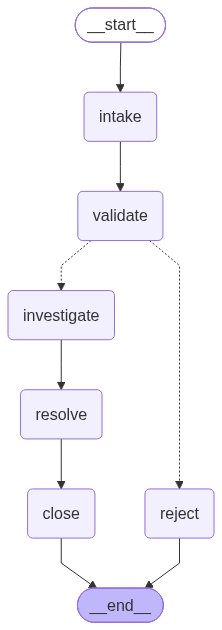

In [21]:
# Display the compiled workflow graph.
display(Image(app.get_graph().draw_mermaid_png()))

In [22]:
# Print the executed path for every test complaint.
for r in results:
    print(" → ".join(r["workflow_path"]))

intake → validate → investigate → resolve → close
intake → validate → investigate → resolve → close
intake → validate → investigate → resolve → close
intake → validate → investigate → resolve → close
intake → validate → reject


---
## Step 6: Compare with LangChain [YOUR TURN]

Ask the same complaint with **one LLM call** (no graph, no lore). Then fill in the table.

In [23]:
# Ask the same valid complaint with one direct LLM call.
answer = llm.invoke([HumanMessage(content=test_complaints[0])])
print("Direct LLM answer (valid complaint):")
print(answer.content)

# Ask the invalid complaint directly, without validation or lore.
invalid_answer = llm.invoke([HumanMessage(content=test_complaints[-1])])
print("\nDirect LLM answer (invalid complaint):")
print(invalid_answer.content)

Direct LLM answer (valid complaint):
To predict when the Downside Up portal opens, you can follow these steps:

1. **Historical Data**: Gather data on the opening times of the portal over a period of time. Look for patterns or trends in the times it opens.

2. **Identify Patterns**: Analyze the data for any recurring patterns. For example, does it open at similar times on certain days of the week? Are there specific intervals between openings?

3. **External Factors**: Consider any external factors that might influence the opening times, such as events, lunar cycles, or other relevant occurrences.

4. **Create a Model**: If you have enough data, you could create a predictive model using statistical methods or machine learning techniques to forecast future opening times based on past behavior.

5. **Stay Updated**: Keep an eye on any announcements or updates from the source of the portal, as they may provide clues or schedules for when it will open.

6. **Community Insights**: Engage wi

| | LangGraph | One LLM call |
|---|---|---|
| Same answer every run? | More consistent because the path and prompts are fixed, but LLM output can still vary. | No guarantee; the model answers directly. |
| Invalid complaint rejected? | Yes, through validation and conditional routing to `reject`. | No built-in rejection step. |
| Path visible? | Yes: `workflow_path` records every node. | No. |
| Source of each claim? | Yes: the investigation stores the lore in `evidence`. | No explicit source trace. |
| Best for which client case? | Strict, auditable complaint processing. | Fast, open-ended responses. |

---
## Extensions [OPTIONAL]

- Parallel investigation
- Retry logic
- Human approval before `resolve`
- Save state with a checkpointer

In [ ]:
# YOUR TURN (optional)

# TODO

---
## ✅ Write `lab_proof.md` [YOUR TURN]

```markdown
# Lab Proof: NormalObjects Complaint Processor

## 1. What I built
## 2. Query
## 3. Evidence (workflow path + log lines + lore used)
## 4. Final output
## 5. Trace (which claim comes from which lore line?)
## 6. Failure or limitation
## 7. LangGraph vs. one LLM call
```

**Before you submit:**
- [ ] No API keys or `.env`
- [ ] Only lab files
- [ ] `lab_proof.md` is the entry point

---
### Troubleshooting

| Problem | Fix |
|---|---|
| Workflow stops at a node | Check node return values and edges |
| Routing doesn't work | Routing function must return a name from the mapping |
| State not updating | Return the updated fields; keys must exist in the state |
| Valid complaint rejected | Print the raw category (dot, capital, newline?) |
| `draw_mermaid_png()` fails | Use `print(app.get_graph().draw_mermaid())` |